특성 중요도 Top 10 (%)
   Feature  Importance
    시도_경기도   41.109230
  시도_서울특별시   25.212042
  시도_인천광역시   12.184811
   시도_경상북도    5.072621
시도_세종특별자치시    4.981823
      월 숫자    3.282421
   시도_전라남도    2.356656
  시도_울산광역시    0.866090
  시도_광주광역시    0.787988
  시도_부산광역시    0.755549


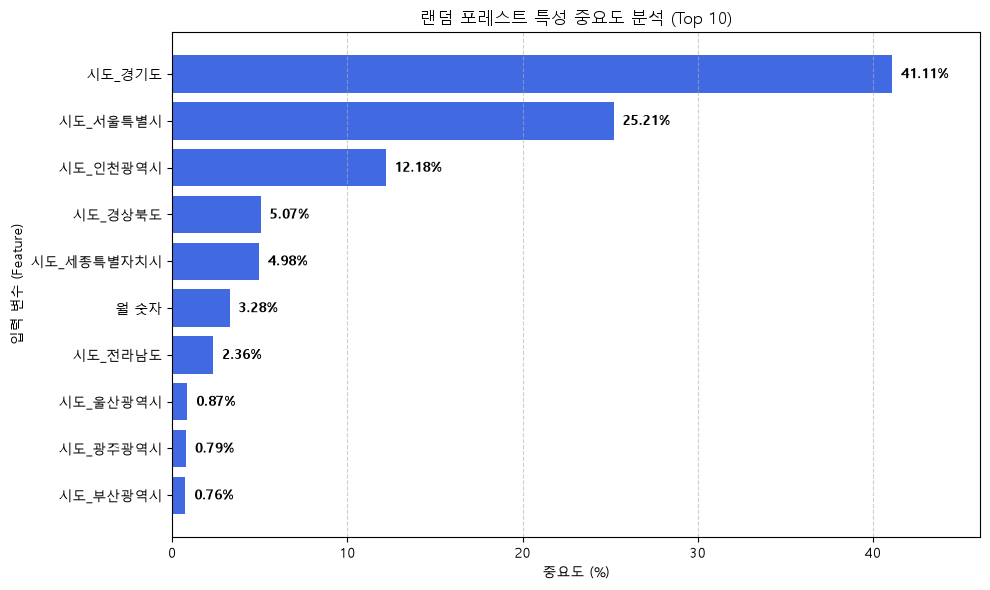

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split

# 한글 폰트, 마이너스 기호 설정
plt.rc('font', family = 'Malgun Gothic')
plt.rcParams['axes.unicode_minus'] = False

# 데이터 불러오기, 랜덤포레스트 모델 학습 
# 우편번호 5자리 앞 '0'이 사라지지 않게 문자열로 저장
data = pd.read_csv('preprocessed_parcel_data.csv', encoding = 'utf-8', dtype={'우편번호 5자리':str})

# 범주형 변수 시, 도를 원핫인코딩(0과 1로) (머신러닝 학습)
df_ml = pd.get_dummies(data, columns=['시도'], drop_first=True)

# 예측에 불필요한거 제외 후 입력변수 (X)
X = df_ml.drop(columns=['우편번호 5자리','월','물동량'])

# 모델이 예측해야 할 목표 변수: '물동량' (y)
y = df_ml['물동량']

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42)

# 결정 트리 100개 생성, 병렬 연산하는 랜덤포레스트 모델 정의
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

# 특성 중요도 추출 및 정렬 (Top 10)
# 특성 중요도는 여기서 택배 물동량을 예측할 때 어떤 변수를 얼마나 참고했는가? 백분율로 나타낸다.
feature_imp_df = pd.DataFrame({'Feature':X.columns, 
                               'Importance': rf_model.feature_importances_ *100,}).sort_values(by='Importance', ascending=False)
# 백분율로 변환

# 중요도가 높은 상위 10개 변수 추출하고 저장
top10 = feature_imp_df.head(10)

print('특성 중요도 Top 10 (%)')
print(top10.to_string(index=False))

# 시각화
# 수평 막대 그래프 사용 (1위가 맨 위에 오도록 정렬 (역순))
top10_rev = top10.iloc[::-1]

plt.figure(figsize=(10,6))
plt.barh(top10_rev['Feature'], top10_rev['Importance'], color = 'royalblue')

# 막대 옆에 수치 표시 (위치 (i), 수치(v))
for i, v in enumerate(top10_rev['Importance']):
    plt.text(v + 0.5, i, f'{v:.2f}%', va = 'center', fontweight = 'bold')

plt.title('랜덤 포레스트 특성 중요도 분석 (Top 10)')
plt.xlabel('중요도 (%)')
plt.ylabel('입력 변수 (Feature)')
plt.xlim(0, top10['Importance'].max() +5)
plt.grid(axis='x', linestyle ='--', alpha = 0.6)
plt.tight_layout()

plt.savefig('feature_importance.png', dpi = 300)
plt.show()